# Experiment 3: Regression Analysis using Linear and Regularized Models
Source: `experiment.org` (Org Babel); this notebook is the executed Jupyter version.


**Sri Sivasubramaniya Nadar College of Engineering, Chennai**  
*(An Autonomous Institution Affiliated to Anna University)*  
ICS1512 — Machine Learning Algorithms Laboratory


| Field | Value |
|---|---|
| Experiment No. | 3 |
| Experiment Title | Regression Analysis using Linear and Regularized Models |
| Student Name | Emmanuel Maximus Ravichandran |
| Register Number | 3122247001015 |
| Faculty | Dr. Poreddy Ajay Kumar Reddy |
| Submission Date |  |

## Aim and Objective


To implement Linear, Ridge, Lasso and Elastic Net regression for predicting a continuous
target (the loan amount sanctioned), to tune the regularisation hyperparameters with Grid
Search and Randomized Search using 5-fold cross-validation, to evaluate all models with MAE,
MSE, RMSE, R2 and training time, to visualise model behaviour and errors, and to analyse
overfitting, underfitting and the bias-variance trade-off.

## Dataset Description


| Dataset Name | Predict Loan Amount Data |
|---|---|
| Dataset Source | Kaggle (phileinsophos/predict-loan-amount-data) |
| Number of Samples | 30000 raw; 29322 with a valid target; 21457 approved loans used for regression |
| Number of Features | 20 after dropping Customer ID, Name and Property ID (7 numeric, 13 categorical or coded) |
| Target Variable | Loan Sanction Amount (USD), continuous |
| Missing Values | NaN in 11 columns; placeholder -999 in 4 columns (target, Property Price, Current Loan Expenses, Co-Applicant) |
| Train-Test Split | 80 / 20 random split of the approved loans, random_state = 42 |

## Preprocessing Steps

### Setup and Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, time, platform, multiprocessing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import (train_test_split, KFold, GridSearchCV, RandomizedSearchCV,
                                     cross_validate, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
os.makedirs("figures", exist_ok=True)
sns.set_style("whitegrid")
RS = 42
np.random.seed(RS)
print("setup complete")

setup complete


### Load Dataset and Inspect Missing Values

In [2]:
raw = pd.read_csv("data/loan_train.csv")
TARGET = "Loan Sanction Amount (USD)"
print("Raw shape:", raw.shape)
miss = raw.isna().sum()
print("Columns with NaN:\n", miss[miss > 0].to_string())
sentinel = (raw.select_dtypes(include="number") == -999).sum()
print("\nColumns with the -999 placeholder:\n", sentinel[sentinel > 0].to_string())

Raw shape: (30000, 24)
Columns with NaN:
 Gender                           53
Income (USD)                   4576
Income Stability               1683
Type of Employment             7270
Current Loan Expenses (USD)     172
Dependents                     2493
Credit Score                   1703
Has Active Credit Card         1566
Property Age                   4850
Property Location               356
Loan Sanction Amount (USD)      340

Columns with the -999 placeholder:
 Current Loan Expenses (USD)    177
Co-Applicant                   168
Property Price                 352
Loan Sanction Amount (USD)     338


*Inference:* The raw file has 30000 rows and 24 columns. Eleven columns contain true NaN values (for
example Type of Employment 7270, Property Age 4850 and Income 4576), and four columns
contain the placeholder -999: Property Price (352), the target Loan Sanction Amount (338),
Current Loan Expenses (177) and Co-Applicant (168). The -999 entries are invalid codes, so
treating them as real numbers would badly distort means, scaling and regression
coefficients.

### Cleaning and Target Selection


The columns Customer ID, Name and Property ID are identifiers and are dropped. The
placeholder -999 is not a real value and is converted to NaN so that it can be imputed like
any other missing entry. Rows with no valid target are removed. A sanctioned amount of
exactly zero means that the application was rejected or not processed, not a very small
loan, so the regression models are fitted on the approved applications only.

In [3]:
df = raw.drop(columns=["Customer ID", "Name", "Property ID"]).replace(-999, np.nan)
df = df.dropna(subset=[TARGET])
n_valid = len(df)
n_zero = int((df[TARGET] == 0).sum())
df = df[df[TARGET] > 0].reset_index(drop=True)
# Property Type and Co-Applicant are category codes, not quantities
for c in ["Property Type", "Co-Applicant"]:
    df[c] = df[c].map(lambda v: np.nan if pd.isna(v) else str(int(v))).astype(object)
num_cols = df.drop(columns=[TARGET]).select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols + [TARGET]]
print("Rows with valid target:", n_valid, "| zero-amount rows removed:", n_zero, f"({n_zero/n_valid:.1%})")
print("Approved loans used for regression:", len(df))
print("Numeric features    :", num_cols)
print("Categorical features:", cat_cols)

Rows with valid target: 29322 | zero-amount rows removed: 7865 (26.8%)
Approved loans used for regression: 21457
Numeric features    : ['Age', 'Income (USD)', 'Loan Amount Request (USD)', 'Current Loan Expenses (USD)', 'Dependents', 'Credit Score', 'No. of Defaults', 'Property Age', 'Property Price']
Categorical features: ['Gender', 'Income Stability', 'Profession', 'Type of Employment', 'Location', 'Expense Type 1', 'Expense Type 2', 'Has Active Credit Card', 'Property Type', 'Property Location', 'Co-Applicant']


*Inference:* After removing identifiers and invalid targets, 29322 rows remain, of which 7865 (26.8%)
have a sanctioned amount of exactly zero. These are rejected applications rather than small
loans, so the regression is fitted on the remaining 21457 approved loans. The features split
into 9 numeric columns and 11 categorical columns (Property Type and Co-Applicant are
category codes and are treated as categorical).

## Exploratory Data Analysis

### Target Variable Distribution

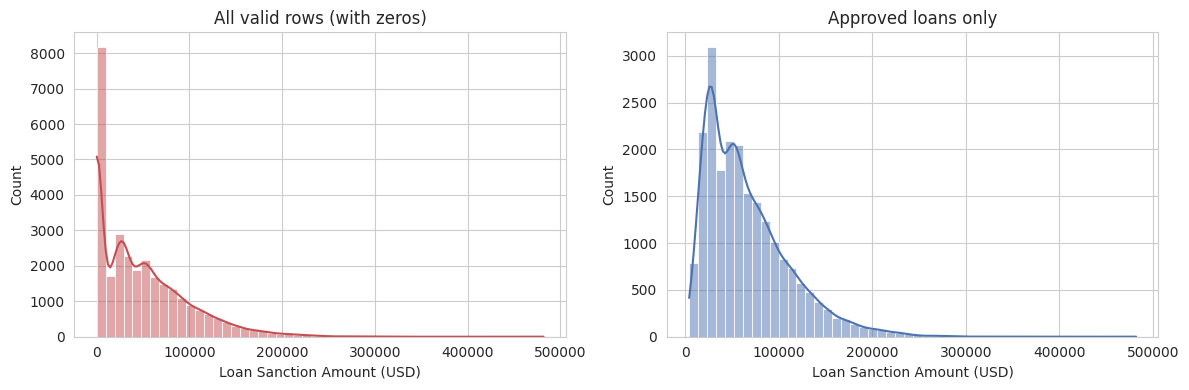

In [4]:
full = raw[TARGET].replace(-999, np.nan).dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(full, bins=50, kde=True, ax=ax[0], color="#C44E52"); ax[0].set_title("All valid rows (with zeros)")
sns.histplot(df[TARGET], bins=50, kde=True, ax=ax[1], color="#4C72B0"); ax[1].set_title("Approved loans only")
for a in ax: a.set_xlabel("Loan Sanction Amount (USD)")
plt.tight_layout()
plt.savefig("figures/fig_01_target_distribution.png", dpi=110, bbox_inches="tight")
plt.show()

In [5]:
print(df[TARGET].describe().round(1).to_string())
print("\nSkewness:", round(df[TARGET].skew(), 3))

count     21457.0
mean      65881.4
std       44858.7
min        4023.2
25%       30310.9
50%       55191.7
75%       89126.8
max      481907.3

Skewness: 1.285


*Inference:* For approved loans the target is right-skewed (skewness 1.29): the mean is 65881 USD and the
median 55192 USD, with a range from 4023 to 481907 USD. The left panel shows why zeros are
excluded: including them adds a large spike at 0 that is a different (rejection) process
from the loan-size distribution in the right panel. A skewed target with a long right tail
also suggests that large loans will have larger absolute errors.

### Feature versus Target

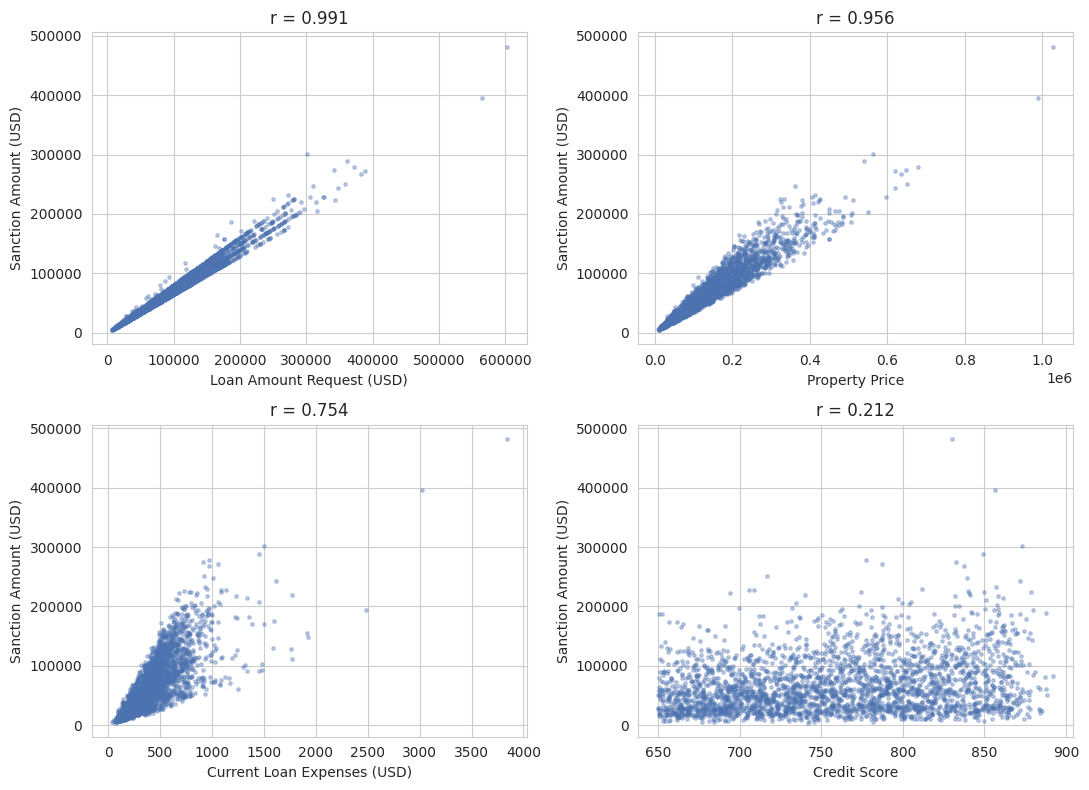

In [6]:
feats = ["Loan Amount Request (USD)", "Property Price", "Current Loan Expenses (USD)", "Credit Score"]
samp = df.sample(3000, random_state=RS)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, f in zip(axes.flat, feats):
    ax.scatter(samp[f], samp[TARGET], s=6, alpha=0.35, color="#4C72B0")
    ax.set_xlabel(f); ax.set_ylabel("Sanction Amount (USD)")
    ax.set_title(f"r = {df[f].corr(df[TARGET]):.3f}")
plt.tight_layout()
plt.savefig("figures/fig_02_feature_vs_target.png", dpi=110, bbox_inches="tight")
plt.show()

In [7]:
print("Correlation of each numeric feature with the target:")
print(df[num_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

Correlation of each numeric feature with the target:
Loan Amount Request (USD)      0.991
Property Price                 0.956
Current Loan Expenses (USD)    0.754
Credit Score                   0.212
Income (USD)                   0.042
Property Age                   0.042
Dependents                     0.016
No. of Defaults               -0.005
Age                           -0.014


*Inference:* The sanctioned amount is almost linear in Loan Amount Request (r = 0.991) and Property Price
(r = 0.956), and moderately related to Current Loan Expenses (r = 0.754). Credit Score has
only a weak positive relation (r = 0.212), and Income, Age, Dependents and Defaults are
essentially uncorrelated with the target (|r| below 0.05). The scatter plots fan out as the
amount grows, so the spread of the error is expected to increase with loan size. A linear
model is clearly appropriate here.

## Implementation Details

### Preprocessing Pipeline and Train-Test Split


Missing numeric values are imputed with the median and then standardised; missing
categorical values are imputed with the most frequent category and one-hot encoded (first
level dropped). Everything is wrapped in a scikit-learn pipeline together with the model, so
during cross-validation the imputer, scaler and encoder are fitted on the training folds
only and no information leaks from the validation fold.

In [8]:
X = df.drop(columns=[TARGET])
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS)
def make_prep():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))]), cat_cols)])
def make(model):
    return Pipeline([("prep", make_prep()), ("model", model)])
prep_check = make_prep().fit(X_train)
feat_names = [n.split("__", 1)[1] for n in prep_check.get_feature_names_out()]
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Features after encoding:", len(feat_names))
print("Train target mean/std:", round(y_train.mean(), 1), "/", round(y_train.std(), 1))

Train: (17165, 20) | Test: (4292, 20)
Features after encoding: 46
Train target mean/std: 65620.1 / 44608.4


*Inference:* The 80/20 split gives 17165 training and 4292 test loans, and the encoded design matrix has
46 columns (9 standardised numeric plus 37 one-hot indicators). With roughly 370 training
rows per feature the problem is far from the high-dimensional regime in which overfitting is
a serious risk. The training target mean (65620) is close to the full-data mean, so the
split is representative.

### Regression Models


Linear Regression minimises the residual sum of squares. The regularised models add a
penalty on the coefficients $\beta$:

\begin{align}
\text{Ridge:}\quad & \min_\beta \; \lVert y - X\beta\rVert_2^2 + \alpha \lVert\beta\rVert_2^2 \\
\text{Lasso:}\quad & \min_\beta \; \tfrac{1}{2n}\lVert y - X\beta\rVert_2^2 + \alpha \lVert\beta\rVert_1 \\
\text{Elastic Net:}\quad & \min_\beta \; \tfrac{1}{2n}\lVert y - X\beta\rVert_2^2 + \alpha\rho \lVert\beta\rVert_1 + \tfrac{\alpha(1-\rho)}{2}\lVert\beta\rVert_2^2
\end{align}

Here $\alpha$ is the regularisation strength and $\rho$ is the Elastic Net `l1_ratio`. Ridge
shrinks all coefficients smoothly and stabilises them under multicollinearity, Lasso can set
coefficients exactly to zero and so performs feature selection, and Elastic Net combines
both behaviours.

### Experimental Setup

In [9]:
print("Python Version      :", platform.python_version())
print("Scikit-Learn Version:", sklearn.__version__)
print("NumPy / Pandas      :", np.__version__, "/", pd.__version__)
print("IDE                 : Emacs Org Babel (Org mode) and Jupyter Notebook")
print("Operating System    :", platform.system(), platform.release())
print("Hardware            :", multiprocessing.cpu_count(), "CPU core(s)")

Python Version      : 3.12.3
Scikit-Learn Version: 1.8.0
NumPy / Pandas      : 2.4.4 / 3.0.2
IDE                 : Emacs Org Babel (Org mode) and Jupyter Notebook
Operating System    : Linux 6.18.44-fc-v114
Hardware            : 1 CPU core(s)


### Hyperparameter Search Space


| Model | Parameter | Values |
|---|---|---|
| Ridge | $\alpha$ | 0.01, 0.1, 1, 10, 100 |
| Lasso | $\alpha$ | 0.001, 0.01, 0.1, 1, 10 |
| Elastic Net | $\alpha$ | 0.01, 0.1, 1, 10 |
| Elastic Net | ~l1_ratio~ | 0.2, 0.5, 0.8 |
| Validation | 5-fold cross-validation, scoring = R2 |  |

## Performance Tables

### Table 1: Hyperparameter Tuning Summary


GridSearchCV evaluates every combination of the specified space. RandomizedSearchCV samples
a subset of the same space (4 of 5 values for Ridge and Lasso, 6 of the 12 Elastic Net
combinations), which shows how far a cheaper search gets.

In [10]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=RS)
spaces = {"Ridge": (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100]}, 4),
          "Lasso": (Lasso(max_iter=20000), {"model__alpha": [0.001, 0.01, 0.1, 1, 10]}, 4),
          "Elastic Net": (ElasticNet(max_iter=20000), {"model__alpha": [0.01, 0.1, 1, 10], "model__l1_ratio": [0.2, 0.5, 0.8]}, 6)}
grids, rands, rows = {}, {}, []
for name, (est, space, n_it) in spaces.items():
    t0 = time.perf_counter()
    g = GridSearchCV(make(est), space, cv=cv5, scoring="r2", n_jobs=-1).fit(X_train, y_train); tg = time.perf_counter() - t0
    t0 = time.perf_counter()
    r = RandomizedSearchCV(make(est), space, n_iter=n_it, cv=cv5, scoring="r2", random_state=RS, n_jobs=-1).fit(X_train, y_train); tr = time.perf_counter() - t0
    grids[name], rands[name] = g, r
    fmt = lambda s: ", ".join(f"{k.split('__')[1]}={v}" for k, v in s.best_params_.items())
    rows.append([name, "Grid", fmt(g), round(g.best_score_, 5), round(tg, 1)])
    rows.append([name, "Random", fmt(r), round(r.best_score_, 5), round(tr, 1)])
tune_df = pd.DataFrame(rows, columns=["Model", "Search", "Best Parameters", "Best CV R2", "Time (s)"])
print(tune_df.to_string(index=False))

      Model Search          Best Parameters  Best CV R2  Time (s)
      Ridge   Grid                  alpha=1     0.98613       2.7
      Ridge Random                  alpha=1     0.98613       2.8
      Lasso   Grid                 alpha=10     0.98615      57.2
      Lasso Random                 alpha=10     0.98615      54.3
Elastic Net   Grid alpha=0.01, l1_ratio=0.8     0.98609      12.4
Elastic Net Random l1_ratio=0.8, alpha=0.01     0.98609       6.8


*Inference:* All three models select the same hyperparameters under Grid Search and Randomized Search:
Ridge alpha = 1 (CV R2 0.98613), Lasso alpha = 10 (0.98615) and Elastic Net alpha = 0.01
with `l1_ratio` = 0.8 (0.98609). Randomised search finds the same optimum with fewer fits,
but for such small spaces the saving is modest and Lasso is dominated by slow convergence at
small alpha. The CV R2 values are practically identical (differences in the fifth decimal),
which shows that the score surface is very flat around the optimum. Note that Lasso's best
alpha lies on the upper edge of the prescribed grid; the validation curve shown later is
flat beyond it, so a wider grid would not change the conclusion.

In [11]:
tuned = {"Linear Regression": make(LinearRegression()),
         "Ridge": make(Ridge(**{k.split("__")[1]: v for k, v in grids["Ridge"].best_params_.items()})),
         "Lasso": make(Lasso(max_iter=20000, **{k.split("__")[1]: v for k, v in grids["Lasso"].best_params_.items()})),
         "Elastic Net": make(ElasticNet(max_iter=20000, **{k.split("__")[1]: v for k, v in grids["Elastic Net"].best_params_.items()}))}
print({k: v.named_steps["model"].get_params().get("alpha", "-") for k, v in tuned.items()})

{'Linear Regression': '-', 'Ridge': 1, 'Lasso': 10, 'Elastic Net': 0.01}


### Table 2: Cross-Validation Performance (K = 5)

In [12]:
scoring = {"MAE": "neg_mean_absolute_error", "MSE": "neg_mean_squared_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
cvrows = {}
for name, pipe in tuned.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv5, scoring=scoring, n_jobs=-1)
    cvrows[name] = {"MAE": -s["test_MAE"].mean(), "MSE": -s["test_MSE"].mean(), "RMSE": -s["test_RMSE"].mean(), "R2": s["test_R2"].mean()}
cv_df = pd.DataFrame(cvrows).T
print(cv_df.round({"MAE": 1, "MSE": 0, "RMSE": 1, "R2": 5}).to_string())

                      MAE         MSE    RMSE       R2
Linear Regression  3621.7  27594238.0  5252.4  0.98613
Ridge              3621.3  27593151.0  5252.3  0.98613
Lasso              3613.2  27549943.0  5248.2  0.98615
Elastic Net        3620.5  27664473.0  5259.0  0.98609


*Inference:* All four models reach a cross-validated R2 of about 0.986 and an RMSE of about 5250 USD,
with MAE near 3615 USD. Lasso is marginally best (RMSE 5248, MAE 3613) and Elastic Net
marginally worst (5259), but the gaps of 1 to 10 USD are tiny compared with the typical
fold-to-fold variation, so the models are statistically indistinguishable in cross-
validation. Linear Regression is therefore already an excellent fit and regularisation adds
almost nothing in accuracy.

### Table 3: Test Set Performance

In [13]:
test_rows, fitted, preds, train_rmse = {}, {}, {}, {}
for name, pipe in tuned.items():
    times = []
    for _ in range(3):
        t0 = time.perf_counter(); pipe.fit(X_train, y_train); times.append(time.perf_counter() - t0)
    p = pipe.predict(X_test)
    fitted[name], preds[name] = pipe, p
    train_rmse[name] = float(np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))))
    mse = mean_squared_error(y_test, p)
    test_rows[name] = {"MAE": mean_absolute_error(y_test, p), "MSE": mse, "RMSE": np.sqrt(mse),
                       "R2": r2_score(y_test, p), "Train Time (s)": float(np.median(times))}
test_df = pd.DataFrame(test_rows).T
print(test_df.round({"MAE": 1, "MSE": 0, "RMSE": 1, "R2": 5, "Train Time (s)": 4}).to_string())

                      MAE         MSE    RMSE       R2  Train Time (s)
Linear Regression  3746.8  31203654.0  5586.0  0.98514          0.1138
Ridge              3746.4  31185139.0  5584.4  0.98515          0.0875
Lasso              3733.9  30521559.0  5524.6  0.98547          0.1902
Elastic Net        3747.7  31453446.0  5608.3  0.98503          0.6126


*Inference:* On the held-out test set Lasso is again best (RMSE 5525, MAE 3734, R2 0.9855), followed by
Ridge (5584), Linear Regression (5586) and Elastic Net (5608). The spread between the best
and worst model is only about 1.5% of the RMSE. All models explain about 98.5% of the
variance of the sanctioned amount, and the test RMSE is a little higher than the CV RMSE
(about 5586 against 5252 for Linear Regression), which is the usual optimism of cross-
validation and the effect of a different random subset. Training takes well under a second
for every model: Ridge and Linear Regression are fastest (about 0.1 s), Lasso is roughly
twice as slow and Elastic Net is the slowest, several times slower than Ridge, because the
coordinate-descent solvers need many iterations.

### Table 4: Coefficient Comparison

In [14]:
coef_df = pd.DataFrame({n: p.named_steps["model"].coef_ for n, p in fitted.items()}, index=feat_names)
top = coef_df["Linear Regression"].abs().sort_values(ascending=False).index[:10]
print("Ten largest coefficients of Linear Regression (standardised features):")
ct = coef_df.loc[top].rename(columns={"Linear Regression": "Linear", "Elastic Net": "ENet"}).round(1) + 0.0
ct.index = [i[:36] for i in ct.index]
print(ct.to_string())
print("\nCoefficients exactly zero:", {n: int((coef_df[n] == 0).sum()) for n in coef_df}, "of", len(coef_df))
print("Coefficient L2 norm      :", {n: round(float(np.linalg.norm(coef_df[n])), 1) for n in coef_df})

Ten largest coefficients of Linear Regression (standardised features):
                                       Linear    Ridge    Lasso     ENet
Loan Amount Request (USD)             43243.4  43212.7  43224.7  42170.0
Profession_Maternity leave            -9186.1  -3918.2      0.0   -246.9
Credit Score                           2977.5   2977.5   2987.6   2986.9
Profession_Pensioner                  -1731.3   -365.6   -520.9   -540.4
Co-Applicant_1                        -1569.5  -1566.1  -1126.6  -1448.3
Profession_Unemployed                 -1412.1    -25.5      0.0     -3.0
Type of Employment_Waiters/barmen st  -1055.3  -1035.1      0.0   -642.4
Profession_Working                     -968.5    392.8      0.0    103.2
Profession_Commercial associate        -860.8    500.8     81.0    213.2
Type of Employment_Private service s   -670.9   -659.4      0.0   -425.1

Coefficients exactly zero: {'Linear Regression': 0, 'Ridge': 0, 'Lasso': 26, 'Elastic Net': 0} of 46
Coefficient L2 norm     

*Inference:* Loan Amount Request dominates the model with a coefficient of about 43000 USD per standard
deviation, in all four models, followed by Credit Score (about 2980). The shrinkage effect
is visible mainly on rare categories: the Maternity leave profession has a Linear
coefficient of -9186, which Ridge reduces to -3918, Elastic Net to -247 and Lasso sets
exactly to zero, and Unemployed falls from -1412 to -26 (Ridge). Lasso sets 26 of the 46
coefficients exactly to zero, while Ridge and Elastic Net set none; the Lasso model
therefore keeps only 20 features. The overall coefficient norm decreases from 44476 (Linear)
to 43592 (Ridge), 43352 (Lasso) and 42363 (Elastic Net).

### Effect of Tuning versus Default Settings

In [15]:
defaults = {"Ridge": make(Ridge()), "Lasso": make(Lasso(max_iter=20000)), "Elastic Net": make(ElasticNet(max_iter=20000))}
rows = {}
for n, pipe in defaults.items():
    pipe.fit(X_train, y_train)
    d_rmse = np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))
    rows[n] = {"Default RMSE": d_rmse, "Tuned RMSE": test_df.loc[n, "RMSE"], "Default R2": r2_score(y_test, pipe.predict(X_test)), "Tuned R2": test_df.loc[n, "R2"]}
dt = pd.DataFrame(rows).T
print("Default settings: Ridge alpha=1, Lasso alpha=1, Elastic Net alpha=1 and l1_ratio=0.5")
print(dt.round({"Default RMSE": 1, "Tuned RMSE": 1, "Default R2": 5, "Tuned R2": 5}).to_string())

Default settings: Ridge alpha=1, Lasso alpha=1, Elastic Net alpha=1 and l1_ratio=0.5
             Default RMSE  Tuned RMSE  Default R2  Tuned R2
Ridge              5584.4      5584.4     0.98515   0.98515
Lasso              5576.3      5524.6     0.98520   0.98547
Elastic Net       20000.9      5608.3     0.80955   0.98503


*Inference:* Tuning matters mainly for Elastic Net: with the default alpha = 1 and `l1_ratio` = 0.5 it
over-shrinks and reaches only R2 = 0.810 (RMSE 20001), whereas the tuned alpha = 0.01 gives
R2 = 0.985 (RMSE 5608). Lasso also improves from RMSE 5576 to 5525, while Ridge's default
alpha = 1 is already the optimum. The improvement from tuning is therefore large when the
default penalty is too strong and negligible when the data hardly needs regularisation.

### Why Zero-Amount Loans Are Excluded

In [16]:
allv = raw.drop(columns=["Customer ID", "Name", "Property ID"]).replace(-999, np.nan).dropna(subset=[TARGET])
for c in ["Property Type", "Co-Applicant"]:
    allv[c] = allv[c].map(lambda v: np.nan if pd.isna(v) else str(int(v))).astype(object)
Xa, ya = allv.drop(columns=[TARGET]), allv[TARGET]
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=0.2, random_state=RS)
pa = make(LinearRegression()).fit(Xa_tr, ya_tr).predict(Xa_te)
print("Linear Regression on ALL valid rows (zeros kept): R2 =", round(r2_score(ya_te, pa), 4), "| RMSE =", round(float(np.sqrt(mean_squared_error(ya_te, pa))), 1))
print("Linear Regression on approved loans only        : R2 =", round(test_df.loc["Linear Regression", "R2"], 4), "| RMSE =", round(test_df.loc["Linear Regression", "RMSE"], 1))

Linear Regression on ALL valid rows (zeros kept): R2 = 0.6575 | RMSE = 27755.3
Linear Regression on approved loans only        : R2 = 0.9851 | RMSE = 5586.0


*Inference:* Fitting Linear Regression on all valid rows, including the 7865 zero-amount applications,
gives R2 = 0.658 and RMSE = 27755 USD, whereas the approved-only model reaches R2 = 0.985
and RMSE = 5586 USD. A single linear function cannot represent both the rejection (amount of
zero) and the amount-given-approval processes, so excluding the zeros is essential for a
meaningful regression. Predicting whether a loan is approved is a separate classification
task.

## Visualizations

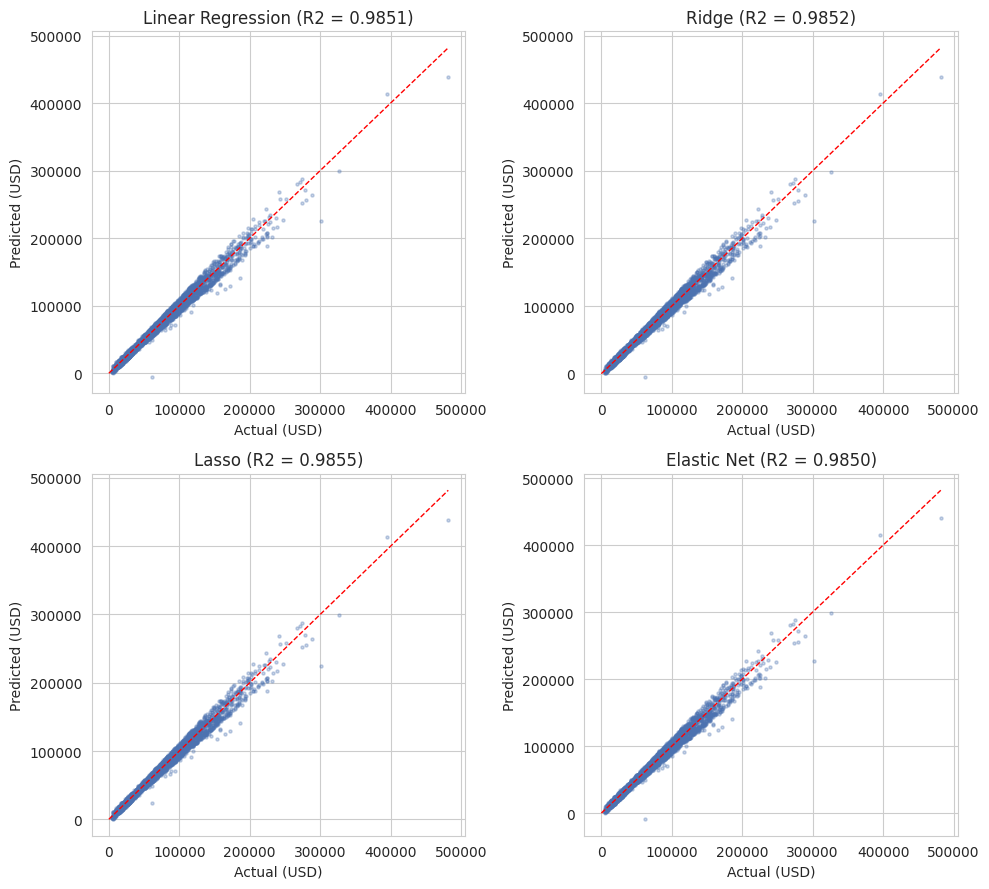

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
lim = [0, max(y_test.max(), max(p.max() for p in preds.values()))]
for ax, (n, p) in zip(axes.flat, preds.items()):
    ax.scatter(y_test, p, s=5, alpha=0.3, color="#4C72B0")
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_title(f"{n} (R2 = {r2_score(y_test, p):.4f})"); ax.set_xlabel("Actual (USD)"); ax.set_ylabel("Predicted (USD)")
plt.tight_layout()
plt.savefig("figures/fig_03_predicted_vs_actual.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* In all four panels the points follow the red identity line closely over the whole range from
about 5000 to 450000 USD, which agrees with the R2 of 0.985. The scatter around the line
widens for larger amounts, and a few very large loans are slightly under- or over-predicted.
The four models are visually indistinguishable, confirming the near-identical metrics.

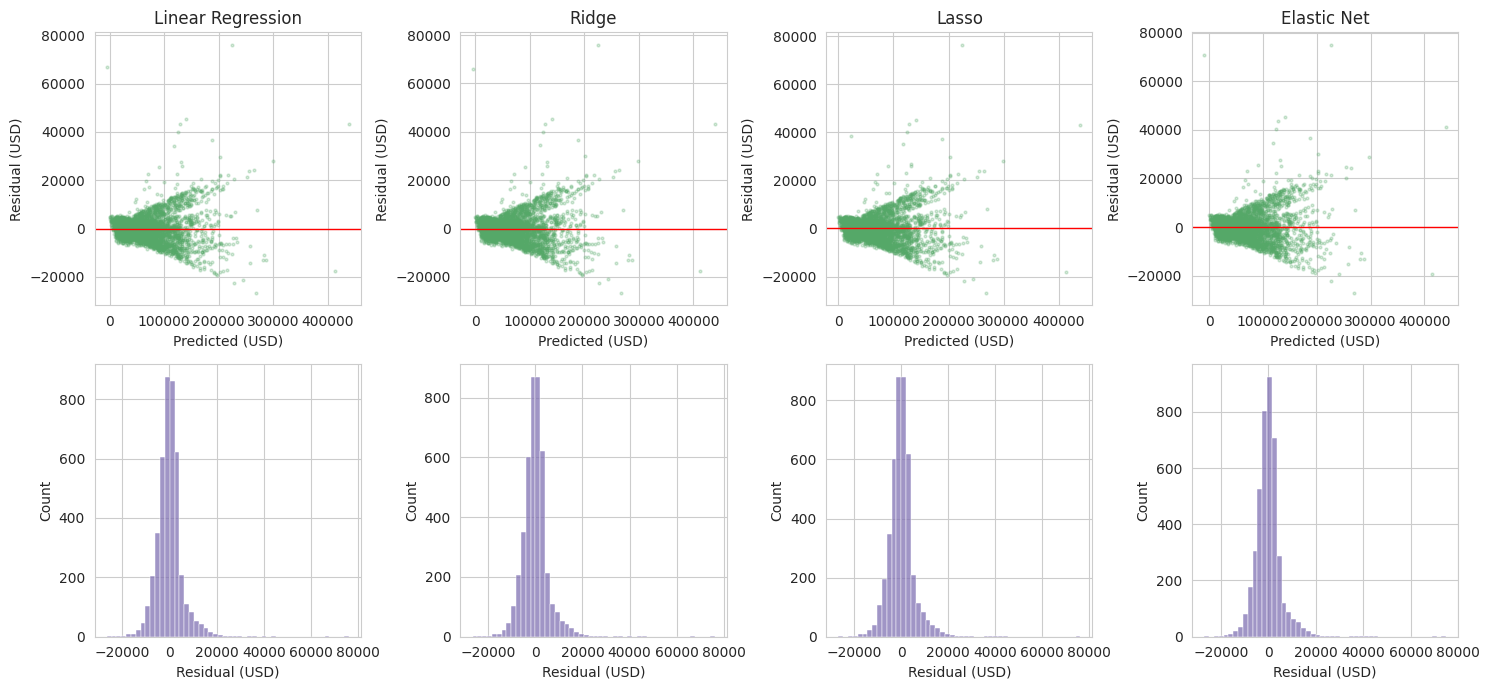

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for j, (n, p) in enumerate(preds.items()):
    r_ = y_test - p
    axes[0, j].scatter(p, r_, s=4, alpha=0.25, color="#55A868"); axes[0, j].axhline(0, color="r", lw=1)
    axes[0, j].set_title(n); axes[0, j].set_xlabel("Predicted (USD)"); axes[0, j].set_ylabel("Residual (USD)")
    sns.histplot(r_, bins=50, ax=axes[1, j], color="#8172B3"); axes[1, j].set_xlabel("Residual (USD)")
plt.tight_layout()
plt.savefig("figures/fig_04_residuals.png", dpi=110, bbox_inches="tight")
plt.show()

In [19]:
for n, p in preds.items():
    r_ = y_test - p
    print(f"{n:18s} mean residual = {r_.mean():8.1f} | std = {r_.std():8.1f} | skew = {r_.skew():.2f}")

Linear Regression  mean residual =     51.9 | std =   5586.4 | skew = 1.93
Ridge              mean residual =     51.8 | std =   5584.8 | skew = 1.92
Lasso              mean residual =     48.1 | std =   5525.1 | skew = 1.69
Elastic Net        mean residual =     51.7 | std =   5608.8 | skew = 2.00


*Inference:* The residuals are centred on zero (mean about 50 USD, standard deviation 5525 to 5609 USD),
but the residual-versus-predicted plots show a funnel shape: the error spread grows with the
predicted amount, which is heteroscedasticity and violates the constant-variance assumption
of ordinary least squares. The histograms are peaked and right-skewed (skewness 1.7 to 2.0),
because a few large loans are under-predicted by up to 75000 USD. A small number of
predictions for the smallest loans are negative, which is not meaningful. A log transform of
the target or a weighted fit would be natural improvements.

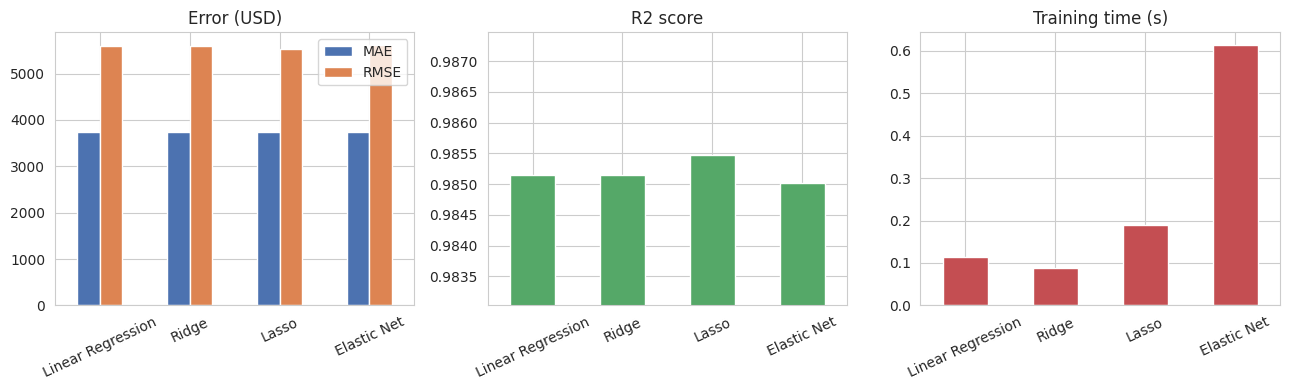

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
test_df[["MAE", "RMSE"]].plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"]); axes[0].set_title("Error (USD)")
test_df["R2"].plot(kind="bar", ax=axes[1], color="#55A868"); axes[1].set_title("R2 score")
axes[1].set_ylim(test_df["R2"].min() - 0.002, test_df["R2"].max() + 0.002)
test_df["Train Time (s)"].plot(kind="bar", ax=axes[2], color="#C44E52"); axes[2].set_title("Training time (s)")
for a in axes: a.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig("figures/fig_05_test_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* The bar charts confirm that Lasso has the lowest MAE and RMSE and the highest R2, but the
differences between models are small. The clearest difference is in training time, where
Elastic Net is several times slower than Ridge. Since accuracy is practically the same, the
cheaper and simpler models (Ridge or Linear) are attractive if speed matters, while Lasso
offers the best accuracy and the sparsest model.

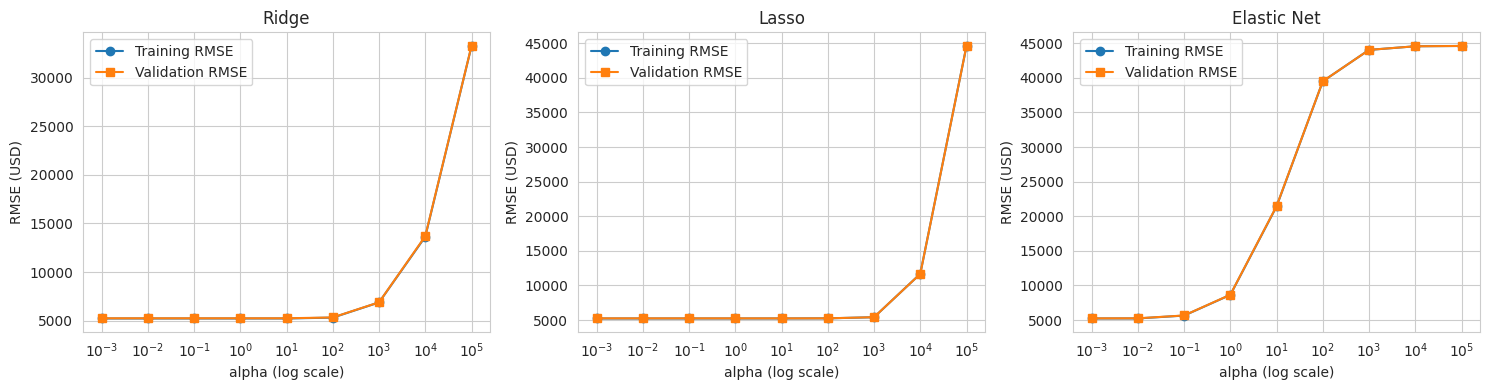

In [21]:
alphas = np.logspace(-3, 5, 9)
best_l1 = grids["Elastic Net"].best_params_["model__l1_ratio"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
curve = {}
for ax, (n, est) in zip(axes, [("Ridge", Ridge()), ("Lasso", Lasso(max_iter=20000)), ("Elastic Net", ElasticNet(l1_ratio=best_l1, max_iter=20000))]):
    tr, va = validation_curve(make(est), X_train, y_train, param_name="model__alpha", param_range=alphas, cv=cv5, scoring="neg_root_mean_squared_error", n_jobs=-1)
    tr, va = -tr.mean(1), -va.mean(1)
    curve[n] = (tr, va)
    ax.semilogx(alphas, tr, "o-", label="Training RMSE"); ax.semilogx(alphas, va, "s-", label="Validation RMSE")
    ax.set_title(n); ax.set_xlabel("alpha (log scale)"); ax.set_ylabel("RMSE (USD)"); ax.legend()
plt.tight_layout()
plt.savefig("figures/fig_06_train_vs_validation.png", dpi=110, bbox_inches="tight")
plt.show()

In [22]:
for n, (tr, va) in curve.items():
    print(n, "- alpha: train RMSE / validation RMSE")
    print("  " + " | ".join(f"{a:g}: {t:.0f}/{v:.0f}" for a, t, v in zip(alphas, tr, va)))

Ridge - alpha: train RMSE / validation RMSE
  0.001: 5231/5252 | 0.01: 5231/5252 | 0.1: 5231/5252 | 1: 5231/5252 | 10: 5233/5253 | 100: 5322/5338 | 1000: 6884/6898 | 10000: 13638/13692 | 100000: 33235/33251
Lasso - alpha: train RMSE / validation RMSE
  0.001: 5231/5252 | 0.01: 5231/5252 | 0.1: 5231/5252 | 1: 5232/5251 | 10: 5236/5248 | 100: 5252/5256 | 1000: 5416/5420 | 10000: 11679/11679 | 100000: 44607/44607
Elastic Net - alpha: train RMSE / validation RMSE
  0.001: 5232/5252 | 0.01: 5240/5259 | 0.1: 5654/5668 | 1: 8643/8665 | 10: 21418/21474 | 100: 39503/39506 | 1000: 44039/44039 | 10000: 44562/44562 | 100000: 44607/44607


*Inference:* For small and moderate alpha the training and validation RMSE are flat at about 5231 and
5252 USD for Ridge and Lasso, and the gap between them is only about 20 USD (0.4%), which
means there is no overfitting even without regularisation. As alpha grows the penalty starts
to dominate and both errors rise together (Ridge 6884 at alpha = 1000, 13638 at 10000; Lasso
11679 at 10000), which is underfitting: the model is biased towards zero coefficients.
Elastic Net rises earlier because its combined penalty is stronger for the same alpha (RMSE
8643 at alpha = 1 and 21418 at alpha = 10). The optimum lies in the flat region before the
rise, which matches the selected alpha values.

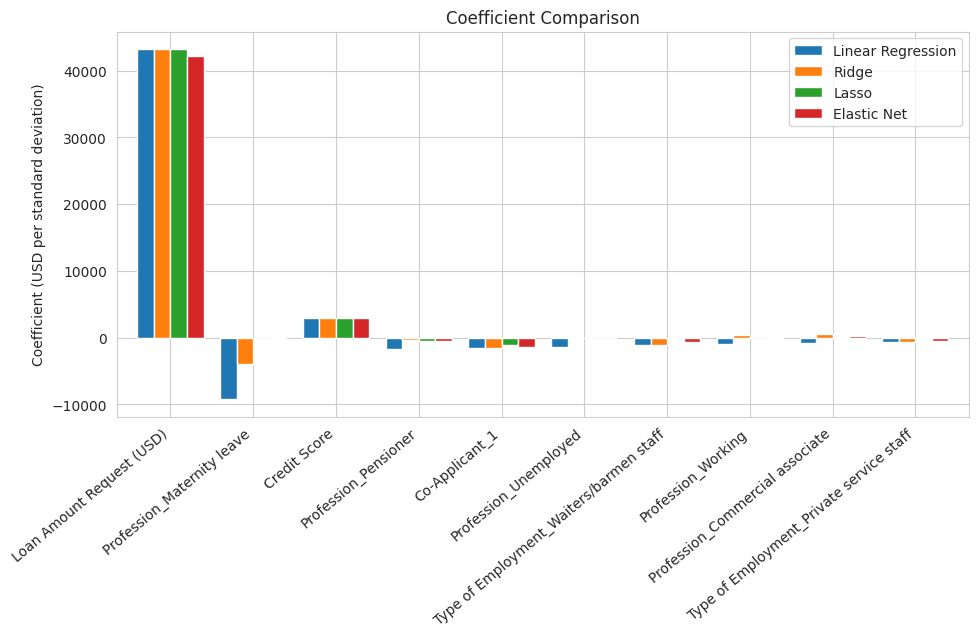

In [23]:
coef_df.loc[top].plot(kind="bar", figsize=(11, 5), width=0.8)
plt.ylabel("Coefficient (USD per standard deviation)"); plt.title("Coefficient Comparison"); plt.xticks(rotation=40, ha="right")
plt.savefig("figures/fig_07_coefficients.png", dpi=110, bbox_inches="tight")
plt.show()

*Inference:* The grouped bars show one dominant coefficient (Loan Amount Request) that is nearly
identical for all models, and a set of much smaller coefficients that differ between models.
For the smaller coefficients, Ridge and Elastic Net bars are visibly shorter than the Linear
Regression bars, and Lasso bars are exactly zero for several of the categories (for example
Maternity leave, Unemployed and Waiters/barmen staff). This is the expected effect: Ridge
shrinks, Lasso selects and Elastic Net does both.

## Overfitting and Underfitting Analysis

In [24]:
gap = pd.DataFrame({"Train RMSE": pd.Series(train_rmse), "CV RMSE": cv_df["RMSE"], "Test RMSE": test_df["RMSE"]})
gap["Test - Train"] = gap["Test RMSE"] - gap["Train RMSE"]
print(gap.round(1).to_string())
print("\nLasso with a very large alpha (underfitting):")
for a in [10, 1000, 10000, 100000]:
    m = make(Lasso(alpha=a, max_iter=20000)).fit(X_train, y_train)
    nz = int((m.named_steps["model"].coef_ != 0).sum())
    print(f"  alpha={a:>6}: test RMSE = {np.sqrt(mean_squared_error(y_test, m.predict(X_test))):9.1f}, R2 = {r2_score(y_test, m.predict(X_test)):7.4f}, non-zero coefficients = {nz}")

                   Train RMSE  CV RMSE  Test RMSE  Test - Train
Linear Regression      5233.5   5252.4     5586.0         352.5
Ridge                  5233.6   5252.3     5584.4         350.7
Lasso                  5237.6   5248.2     5524.6         287.0
Elastic Net            5242.5   5259.0     5608.3         365.8

Lasso with a very large alpha (underfitting):


  alpha=    10: test RMSE =    5524.6, R2 =  0.9855, non-zero coefficients = 20
  alpha=  1000: test RMSE =    5712.9, R2 =  0.9845, non-zero coefficients = 3


  alpha= 10000: test RMSE =   12132.5, R2 =  0.9299, non-zero coefficients = 1
  alpha=100000: test RMSE =   45849.4, R2 = -0.0008, non-zero coefficients = 0


*Inference:* The training RMSE (5234 to 5243), CV RMSE (5248 to 5259) and test RMSE (5525 to 5608) are
all close, with a test-minus-train gap of only 287 to 366 USD (about 5% to 7%), so none of
the models overfits noticeably. Lasso has the smallest generalisation gap (287 USD) and the
best test RMSE. Underfitting appears only when regularisation is far too strong: Lasso with
alpha = 1000 keeps 3 coefficients and has RMSE 5713, with alpha = 10000 it keeps a single
coefficient and RMSE rises to 12133 (R2 = 0.930), and with alpha = 100000 all coefficients
are zero and R2 is about 0, equal to predicting the mean.

Difference between training and validation errors: the gap is very small for every model
(about 20 USD between training and cross-validation RMSE and about 290 to 370 USD between
training and test RMSE), which is a sign of a well-fitted model with low variance.

Effect of regularisation strength: weak regularisation (alpha up to about 10 for Ridge and
100 for Lasso) leaves the error unchanged, while strong regularisation increases both
training and validation errors together, which is the signature of underfitting rather than
of reduced overfitting.

Improvement in generalisation after tuning: tuning improves the test RMSE of Lasso from 5576
to 5525 USD and rescues Elastic Net from a badly underfit default (RMSE 20001) to 5608, but
because plain Linear Regression already generalises well (test RMSE 5586), the gain over the
unregularised baseline is only about 1% at best.

## Bias-Variance Analysis


To measure the bias-variance behaviour directly, each tuned model is refitted on 30
bootstrap resamples of the training set. The variance of the predictions on the fixed test
set across the resamples estimates the variance term, and the squared difference between the
average prediction and the true value estimates bias squared plus noise. The standard
deviation of each coefficient across the resamples measures coefficient stability.

In [25]:
from sklearn.base import clone
B = 30
rng = np.random.default_rng(RS)
prep_fixed = make_prep().fit(X_train)
Xt, Xe = prep_fixed.transform(X_train), prep_fixed.transform(X_test)
yt = y_train.values
base = {n: p.named_steps["model"] for n, p in tuned.items()}
store = {n: [] for n in base}
coefs = {n: [] for n in base}
for b in range(B):
    idx = rng.integers(0, len(yt), len(yt))
    for n, mdl in base.items():
        m = clone(mdl).fit(Xt[idx], yt[idx])
        store[n].append(m.predict(Xe)); coefs[n].append(m.coef_)
rows = {}
for n in base:
    P = np.array(store[n]); C = np.array(coefs[n])
    rows[n] = {"Bias^2 + noise": float(np.mean((P.mean(0) - y_test.values) ** 2)), "Variance": float(P.var(0).mean()),
               "Mean coef. std": float(C.std(0).mean()), "Avg nonzero coef.": float((C != 0).sum(1).mean())}
bv = pd.DataFrame(rows).T
print(bv.round({"Bias^2 + noise": 0, "Variance": 0, "Mean coef. std": 2, "Avg nonzero coef.": 1}).to_string())
print("\nVariance as a share of (bias^2 + noise + variance):")
print((bv["Variance"] / (bv["Bias^2 + noise"] + bv["Variance"])).round(5).to_string())

                   Bias^2 + noise   Variance  Mean coef. std  Avg nonzero coef.
Linear Regression      30955015.0  1222534.0          535.47               46.0
Ridge                  30932444.0  1213693.0          357.84               45.1
Lasso                  30559485.0   860420.0           74.74               22.8
Elastic Net            31114502.0  1164885.0          197.60               45.1

Variance as a share of (bias^2 + noise + variance):
Linear Regression    0.03799
Ridge                0.03776
Lasso                0.02738
Elastic Net          0.03609


*Inference:* The bootstrap experiment gives estimates of the variance term of 1.22 million for Linear
Regression, 1.21 million for Ridge, 1.16 million for Elastic Net and 0.86 million for Lasso
(squared USD), while the bias-plus-noise term is about 31 million for all models. Variance
is therefore only 2.7% to 3.8% of the total error and the error is dominated by irreducible
noise and the remaining model bias. Coefficient instability is reduced strongly by
regularisation: the mean standard deviation of a coefficient across resamples falls from 535
(Linear) to 358 (Ridge), 198 (Elastic Net) and 75 (Lasso). Lasso also uses on average only
about 23 of the 46 coefficients per resample.

Bias behaviour of Linear Regression: Linear Regression is unbiased if the true relationship
is linear, and here the bias-plus-noise term (about 31 million) is the same as for the other
models and is mostly caused by the noise and heteroscedasticity visible in the residual
plots, so the linear model has low bias for this problem.

Variance reduction using Ridge and Elastic Net: Ridge and Elastic Net reduce the coefficient
variance (from 535 to 358 and 198) and slightly reduce the prediction variance (1.22 to 1.21
and 1.16 million) at the price of slightly shrinking the estimates, but with 17165 samples
the variance of ordinary least squares is already small, so the gain in total error is
minimal.

Feature sparsity effect in Lasso: Lasso removes 26 of the 46 features (mostly rare
profession and employment categories) and has the lowest prediction variance (0.86 million)
and the most stable coefficients (standard deviation 75), which explains its slightly better
test error.

Overall the bias-variance trade-off is favourable to mild regularisation but is shallow for
this dataset, because the sample size is large and the signal is strongly linear.

## Observations and Conclusion


All four models predict the sanctioned loan amount of approved applications very well: the
test R2 is 0.985 and the test RMSE is 5525 to 5608 USD (about 8.5% of the mean amount) for
every model, with Lasso best (RMSE 5525, MAE 3734) and Elastic Net slightly worst. The
optimal hyperparameters were chosen by 5-fold cross-validation and confirmed by both Grid
and Randomized Search (Ridge alpha = 1, Lasso alpha = 10, Elastic Net alpha = 0.01 with
`l1_ratio` = 0.8); they lie in the flat region of the validation curve before underfitting
begins. The decisive step was not the choice of model but the preprocessing: including the
26.8% zero-amount rejected loans cuts R2 from 0.985 to 0.658. Regularisation brought a small
but consistent benefit: Lasso reduces test RMSE by about 1% relative to Linear Regression,
halves the number of active coefficients (20 of 46) and has the lowest variance, at the cost
of somewhat slower training, while Ridge and Elastic Net mainly stabilise the coefficients.
In the accuracy versus complexity trade-off, Lasso gives the best accuracy with the simplest
model, whereas plain Linear Regression or Ridge is sufficient if interpretability and speed
are the only requirements. Limitations are the heteroscedastic, right-skewed residuals and a
few negative predictions, which a log-transformed target or a two-stage approval-then-amount
model could address.

## References


[1] "Predict Loan Amount Data," Kaggle, 2021. [Online]. Available: https://www.kaggle.com/datasets/phileinsophos/predict-loan-amount-data

[2] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," J. Mach. Learn. Res., vol. 12, pp. 2825-2830, 2011. (Linear Models and Hyperparameter Optimization user guides: https://scikit-learn.org/stable/modules/linear_model.html and https://scikit-learn.org/stable/modules/grid_search.html)

[3] A. E. Hoerl and R. W. Kennard, "Ridge regression: Biased estimation for nonorthogonal problems," Technometrics, vol. 12, no. 1, pp. 55-67, 1970.

[4] R. Tibshirani, "Regression shrinkage and selection via the lasso," J. R. Stat. Soc. B, vol. 58, no. 1, pp. 267-288, 1996.

[5] H. Zou and T. Hastie, "Regularization and variable selection via the elastic net," J. R. Stat. Soc. B, vol. 67, no. 2, pp. 301-320, 2005.

[6] T. Hastie, R. Tibshirani and J. Friedman, The Elements of Statistical Learning, 2nd ed. Springer, 2009.